# Activité pratique n°2 — Modèles génératifs

**Nom :** Mohamed Ouallal  
**Classe :** IADATA — Groupe 4  
**Enseignant :** Mohamed YOUSSFI

## 0. Configuration de l’environnement


In [1]:
import sys
import torch
import torchvision
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torcheval
from torcheval.metrics import MulticlassAccuracy

assert sys.version_info[:2] == (3, 11), "Sélectionner l’environnement Python 3.11 du projet."
assert sys.prefix != sys.base_prefix, "Sélectionner l’environnement virtuel du projet."

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python :", sys.version.split()[0])
print("Environnement virtuel :", sys.prefix)
print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Matplotlib :", matplotlib.__version__)
print("NumPy :", np.__version__)
print("Torcheval :", torcheval.__version__)
print("Appareil :", device)


Matplotlib is building the font cache; this may take a moment.


Python : 3.11.18
Environnement virtuel : /Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv
PyTorch : 2.15.0
Torchvision : 0.29.2
Matplotlib : 3.11.2
NumPy : 2.4.6
Torcheval : 0.0.7
Appareil : cpu


/Users/mohamedouallal/emsi/5IIR/IAGEN/partie2/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Chargement du dataset MNIST



In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))
print("Classes :", train_dataset.classes)


Images d’entraînement : 60000
Images de test : 10000
Classes : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Dimensions des images : torch.Size([128, 1, 28, 28])
Dimensions des étiquettes : torch.Size([128])
Type des images : torch.float32
Type des étiquettes : torch.int64
Valeurs des pixels : [0.0, 1.0]


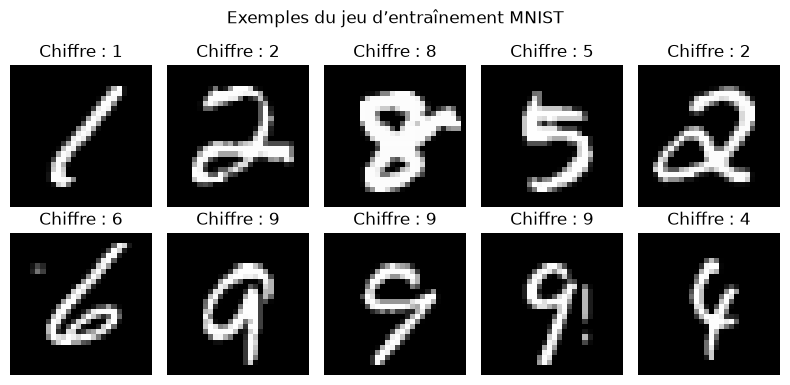

In [3]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des étiquettes :", labels.shape)
print("Type des images :", images.dtype)
print("Type des étiquettes :", labels.dtype)
print(f"Valeurs des pixels : [{images.min().item():.1f}, {images.max().item():.1f}]")

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Chiffre : {labels[i].item()}")
    ax.axis("off")
plt.suptitle("Exemples du jeu d’entraînement MNIST")
plt.tight_layout()
plt.show()


## 2. Modèle discriminatif


In [4]:
from torch import nn

torch.manual_seed(42)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
print(classifier)


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Entraînement


Époque 1/3 | Perte : 0.4100


Époque 2/3 | Perte : 0.1925


Époque 3/3 | Perte : 0.1420


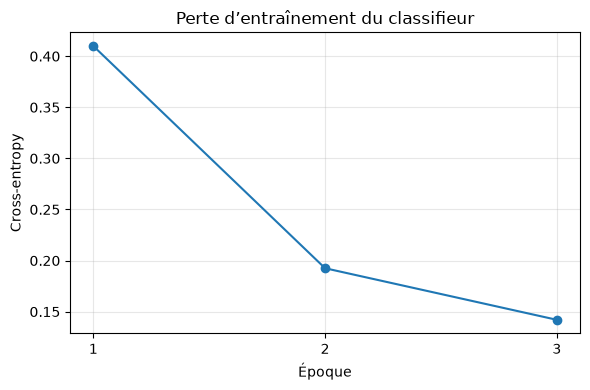

In [5]:
epochs = 3
classifier_losses = []

for epoch in range(epochs):
    classifier.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = classifier(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    classifier_losses.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), classifier_losses, marker="o")
plt.xticks(range(1, epochs + 1))
plt.xlabel("Époque")
plt.ylabel("Cross-entropy")
plt.title("Perte d’entraînement du classifieur")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Évaluation sur le jeu de test


Perte sur le test : 0.1275
Accuracy sur le test : 96.23%
Images bien classées : 9623/10000


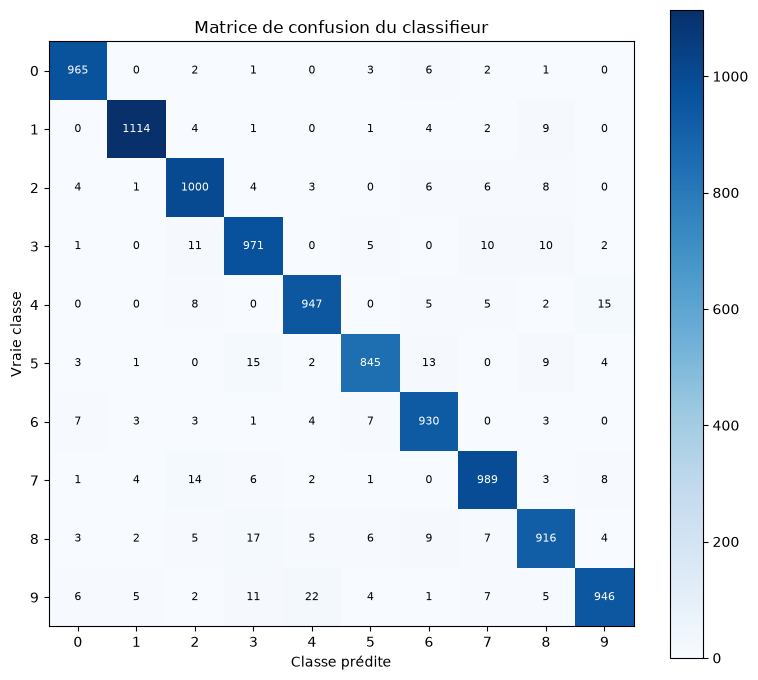

In [6]:
classifier.eval()
metric = MulticlassAccuracy(num_classes=10, device=device)
test_loss = 0.0
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = classifier(images)
        test_loss += criterion(logits, labels).item() * images.size(0)
        metric.update(logits, labels)
        all_predictions.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels.cpu())

classifier_predictions = torch.cat(all_predictions)
classifier_labels = torch.cat(all_labels)
accuracy = metric.compute().item()
correct = (classifier_predictions == classifier_labels).sum().item()

print(f"Perte sur le test : {test_loss / len(test_dataset):.4f}")
print(f"Accuracy sur le test : {accuracy:.2%}")
print(f"Images bien classées : {correct}/{len(test_dataset)}")

# Les lignes correspondent aux vraies classes et les colonnes aux prédictions.
confusion = torch.bincount(
    classifier_labels * 10 + classifier_predictions, minlength=100
).reshape(10, 10)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
for i in range(10):
    for j in range(10):
        value = confusion[i, j].item()
        ax.text(j, i, str(value), ha="center", va="center",
                color="white" if value > confusion.max().item() / 2 else "black",
                fontsize=8)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Vraie classe")
ax.set_title("Matrice de confusion du classifieur")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Images mal classées : 377


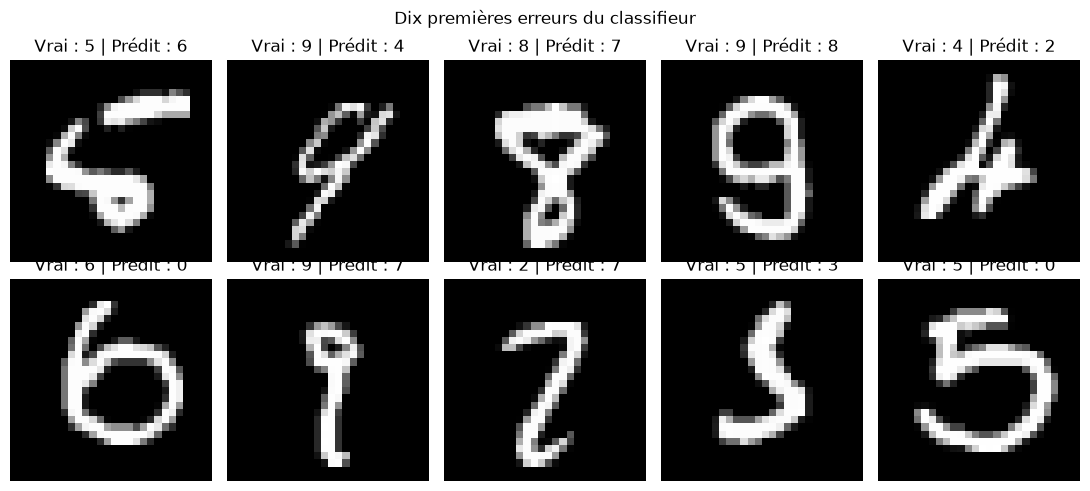

In [7]:
error_indices = (classifier_predictions != classifier_labels).nonzero(as_tuple=True)[0]
print(f"Images mal classées : {len(error_indices)}")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, error_indices[:10].tolist()):
    image, label = test_dataset[index]
    ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {label} | Prédit : {classifier_predictions[index].item()}")
plt.suptitle("Dix premières erreurs du classifieur")
plt.tight_layout()
plt.show()


## 3. Autoencodeur simple



In [3]:
from torch import nn

torch.manual_seed(42)

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

ae = Autoencoder(latent_dim=2).to(device)
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
print(ae)


Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Entraînement


Époque 1/5 | MSE : 0.06476


Époque 2/5 | MSE : 0.05152


Époque 3/5 | MSE : 0.04797


Époque 4/5 | MSE : 0.04540


Époque 5/5 | MSE : 0.04396


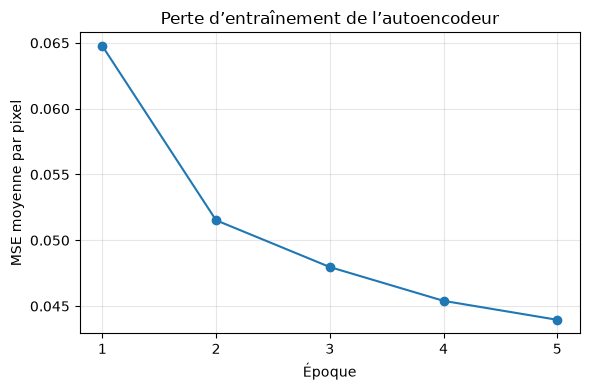

In [4]:
ae_epochs = 5
ae_losses = []
for epoch in range(ae_epochs):
    ae.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        ae_optimizer.zero_grad()
        reconstructions = ae(images)
        loss = ae_criterion(reconstructions, images)
        loss.backward()
        ae_optimizer.step()
        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    ae_losses.append(average_loss)
    print(f"Époque {epoch + 1}/{ae_epochs} | MSE : {average_loss:.5f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, ae_epochs + 1), ae_losses, marker="o")
plt.xticks(range(1, ae_epochs + 1))
plt.xlabel("Époque")
plt.ylabel("MSE moyenne par pixel")
plt.title("Perte d’entraînement de l’autoencodeur")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Évaluation et reconstructions



MSE de test de l’autoencodeur : 0.04341
MSE de test de l’image moyenne : 0.06747


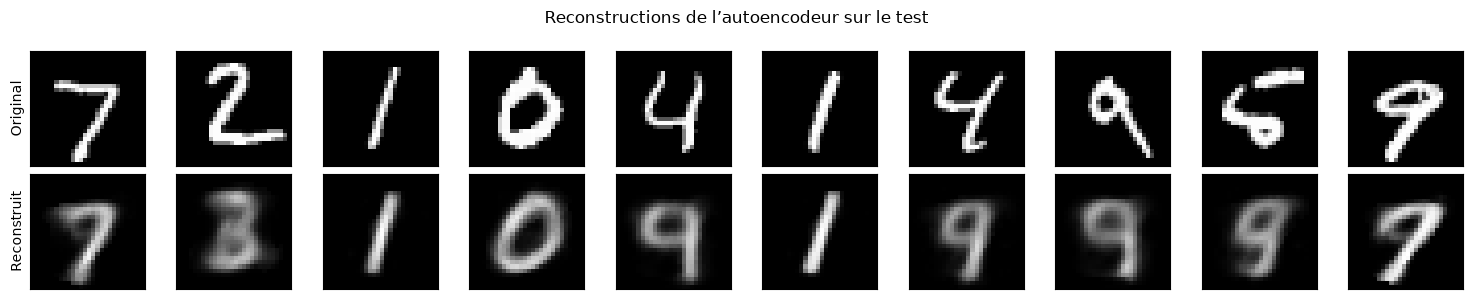

In [5]:
# Cette image de référence utilise uniquement les données d’entraînement.
mean_image = train_dataset.data.float().mean(dim=0).div(255).view(1, 1, 28, 28).to(device)
ae.eval()
ae_squared_error = 0.0
baseline_squared_error = 0.0
pixel_count = 0
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        reconstructions = ae(images)
        ae_squared_error += (reconstructions - images).square().sum().item()
        baseline_squared_error += (mean_image - images).square().sum().item()
        pixel_count += images.numel()

ae_test_mse = ae_squared_error / pixel_count
baseline_test_mse = baseline_squared_error / pixel_count
print(f"MSE de test de l’autoencodeur : {ae_test_mse:.5f}")
print(f"MSE de test de l’image moyenne : {baseline_test_mse:.5f}")

sample_images, _ = next(iter(test_loader))
sample_images = sample_images[:10].to(device)
with torch.no_grad():
    sample_reconstructions = ae(sample_images)
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(sample_images[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(sample_reconstructions[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    for row in range(2):
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")
plt.suptitle("Reconstructions de l’autoencodeur sur le test")
plt.tight_layout()
plt.show()


### Exploration de l’espace latent



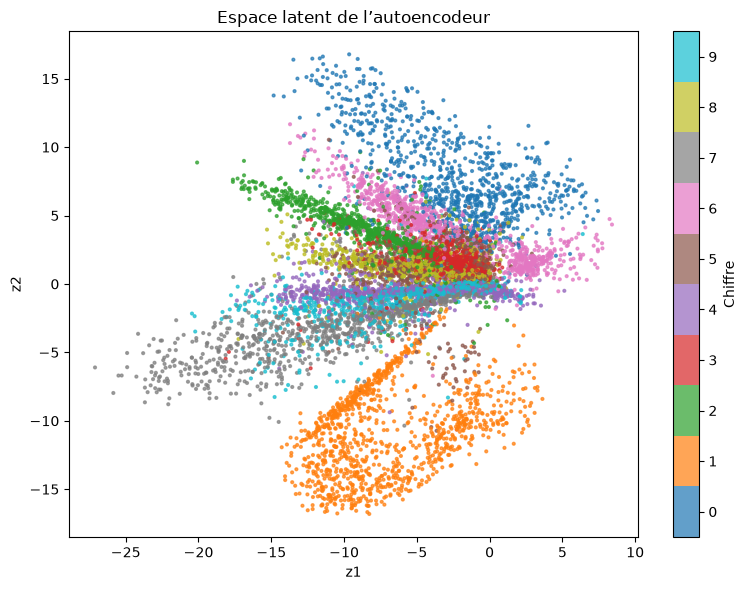

In [6]:
ae.eval()
latent_vectors = []
latent_labels = []
with torch.no_grad():
    for images, labels in test_loader:
        latent_vectors.append(ae.encode(images.to(device)).cpu())
        latent_labels.append(labels)
Z_ae = torch.cat(latent_vectors)
Y_ae = torch.cat(latent_labels)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z_ae[:, 0].numpy(), Z_ae[:, 1].numpy(),
                      c=Y_ae.numpy(), s=4, cmap="tab10", vmin=-0.5, vmax=9.5, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent de l’autoencodeur")
plt.tight_layout()
plt.show()


### Interpolation entre deux chiffres



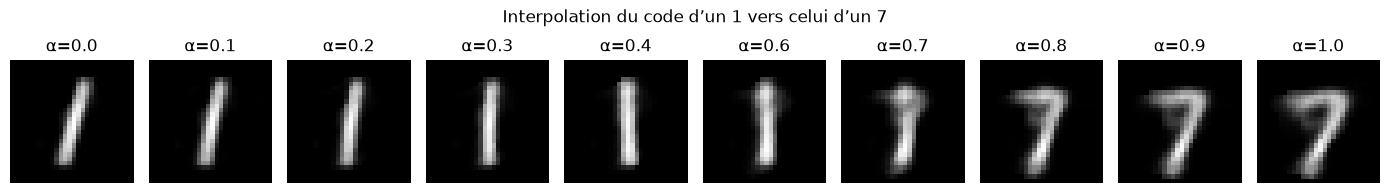

In [7]:
index_1 = (test_dataset.targets == 1).nonzero(as_tuple=True)[0][0].item()
index_7 = (test_dataset.targets == 7).nonzero(as_tuple=True)[0][0].item()
endpoints = torch.stack([test_dataset[index_1][0], test_dataset[index_7][0]]).to(device)
with torch.no_grad():
    z_endpoints = ae.encode(endpoints)
    alphas = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    z_interpolation = (1 - alphas) * z_endpoints[0] + alphas * z_endpoints[1]
    interpolations = ae.decode(z_interpolation).cpu()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(interpolations[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"α={alphas[i].item():.1f}")
    ax.axis("off")
plt.suptitle("Interpolation du code d’un 1 vers celui d’un 7")
plt.tight_layout()
plt.show()


### Décodage d’une grille latente

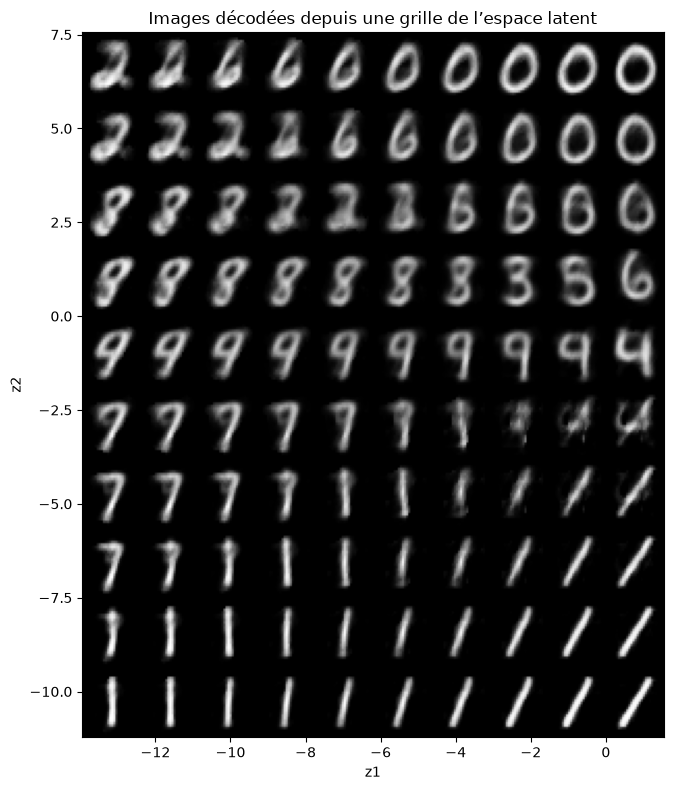

In [8]:
lower = torch.quantile(Z_ae, 0.05, dim=0)
upper = torch.quantile(Z_ae, 0.95, dim=0)
grid_x = torch.linspace(lower[0].item(), upper[0].item(), 10)
grid_y = torch.linspace(upper[1].item(), lower[1].item(), 10)
grid_z = torch.tensor([[x.item(), y.item()] for y in grid_y for x in grid_x], device=device)
with torch.no_grad():
    grid_images = ae.decode(grid_z).cpu()
mosaic = grid_images.view(10, 10, 28, 28).permute(0, 2, 1, 3).reshape(280, 280)
plt.figure(figsize=(8, 8))
plt.imshow(mosaic.numpy(), cmap="gray", vmin=0, vmax=1,
           extent=[lower[0].item(), upper[0].item(), lower[1].item(), upper[1].item()])
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Images décodées depuis une grille de l’espace latent")
plt.tight_layout()
plt.show()


## 4. Autoencodeur variationnel (VAE)


In [3]:
from torch import nn
import torch.nn.functional as F

torch.manual_seed(42)

class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE(latent_dim=2).to(device)
print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Fonction de perte et entraînement

Époque  1/20 | Perte : 194.31 | BCE : 190.17 | KL : 4.14


Époque  2/20 | Perte : 166.53 | BCE : 161.54 | KL : 4.99


Époque  3/20 | Perte : 160.93 | BCE : 155.65 | KL : 5.29


Époque  4/20 | Perte : 157.78 | BCE : 152.37 | KL : 5.41


Époque  5/20 | Perte : 155.65 | BCE : 150.10 | KL : 5.55


Époque  6/20 | Perte : 154.20 | BCE : 148.54 | KL : 5.65


... (10 outputs left out)

Époque 17/20 | Perte : 144.88 | BCE : 138.57 | KL : 6.31


Époque 18/20 | Perte : 144.61 | BCE : 138.24 | KL : 6.37


Époque 19/20 | Perte : 144.19 | BCE : 137.80 | KL : 6.39


Époque 20/20 | Perte : 144.01 | BCE : 137.62 | KL : 6.39


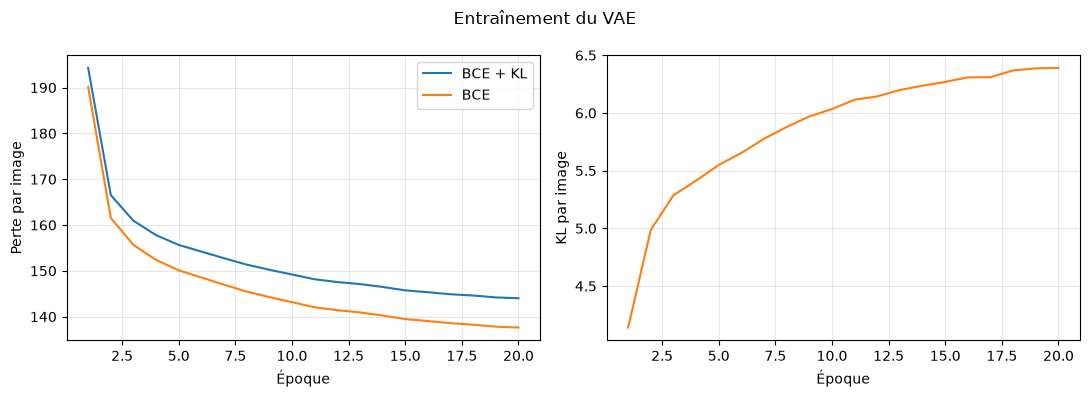

In [4]:
def vae_loss(reconstructions, images, mu, logvar, beta=1.0):
    reconstruction_loss = F.binary_cross_entropy(
        reconstructions, images, reduction="sum"
    )
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp())
    return reconstruction_loss + beta * kl_loss, reconstruction_loss, kl_loss

vae_epochs = 20
beta = 1.0
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_history = {"total": [], "reconstruction": [], "kl": []}

for epoch in range(vae_epochs):
    vae.train()
    total_loss = total_rec = total_kl = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        vae_optimizer.zero_grad()
        reconstructions, mu, logvar = vae(images)
        loss, rec, kl = vae_loss(reconstructions, images, mu, logvar, beta)
        # La moyenne par image sert à la rétropropagation.
        (loss / images.size(0)).backward()
        vae_optimizer.step()
        total_loss += loss.item()
        total_rec += rec.item()
        total_kl += kl.item()

    n = len(train_dataset)
    vae_history["total"].append(total_loss / n)
    vae_history["reconstruction"].append(total_rec / n)
    vae_history["kl"].append(total_kl / n)
    print(f"Époque {epoch + 1:2d}/{vae_epochs} | Perte : {total_loss/n:.2f} | "
          f"BCE : {total_rec/n:.2f} | KL : {total_kl/n:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
steps = range(1, vae_epochs + 1)
axes[0].plot(steps, vae_history["total"], label="BCE + KL")
axes[0].plot(steps, vae_history["reconstruction"], label="BCE")
axes[0].set_ylabel("Perte par image")
axes[0].legend()
axes[1].plot(steps, vae_history["kl"], color="tab:orange")
axes[1].set_ylabel("KL par image")
for ax in axes:
    ax.set_xlabel("Époque")
    ax.grid(alpha=0.3)
fig.suptitle("Entraînement du VAE")
plt.tight_layout()
plt.show()


### Évaluation sur le jeu de test


In [5]:
vae.eval()
torch.manual_seed(123)
test_total = test_rec = test_kl = squared_error = 0.0
pixel_count = 0
vae_mus = []
vae_labels = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        reconstructions, mu, logvar = vae(images)
        loss, rec, kl = vae_loss(reconstructions, images, mu, logvar, beta)
        test_total += loss.item()
        test_rec += rec.item()
        test_kl += kl.item()
        squared_error += (reconstructions - images).square().sum().item()
        pixel_count += images.numel()
        vae_mus.append(mu.cpu())
        vae_labels.append(labels)

n_test = len(test_dataset)
vae_test_mse = squared_error / pixel_count
MU_vae = torch.cat(vae_mus)
Y_vae = torch.cat(vae_labels)
print(f"Images évaluées : {n_test}")
print(f"Perte de test par image : {test_total / n_test:.2f}")
print(f"BCE de test par image : {test_rec / n_test:.2f}")
print(f"KL de test par image : {test_kl / n_test:.2f}")
print(f"MSE de test par pixel : {vae_test_mse:.5f}")


Images évaluées : 10000
Perte de test par image : 145.32
BCE de test par image : 138.99
KL de test par image : 6.33
MSE de test par pixel : 0.03892


### Reconstructions

Pour cet affichage, on décode la moyenne `mu` sans ajouter de bruit. Cela donne une reconstruction déterministe, différente du tirage utilisé pour la perte de test ci-dessus.


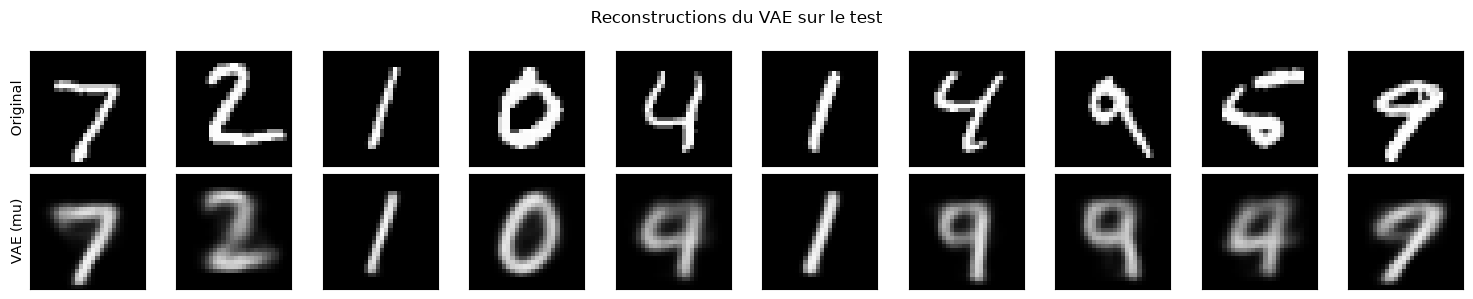

In [6]:
sample_images, _ = next(iter(test_loader))
sample_images = sample_images[:10].to(device)
with torch.no_grad():
    sample_mu, _ = vae.encode(sample_images)
    sample_reconstructions = vae.decode(sample_mu).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(sample_images[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(sample_reconstructions[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    for row in range(2):
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE (mu)")
plt.suptitle("Reconstructions du VAE sur le test")
plt.tight_layout()
plt.show()


### Espace latent


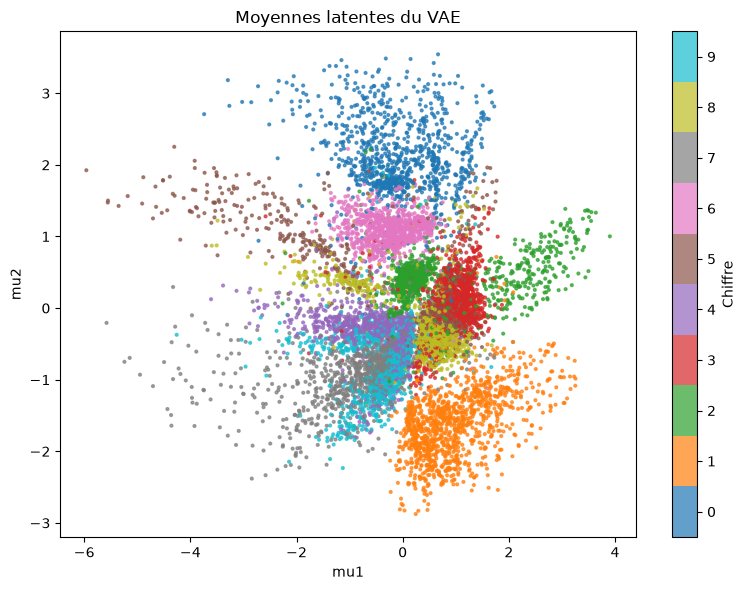

In [7]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(MU_vae[:, 0].numpy(), MU_vae[:, 1].numpy(),
                      c=Y_vae.numpy(), s=4, cmap="tab10", vmin=-0.5, vmax=9.5, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Moyennes latentes du VAE")
plt.tight_layout()
plt.show()


### Génération de nouvelles images

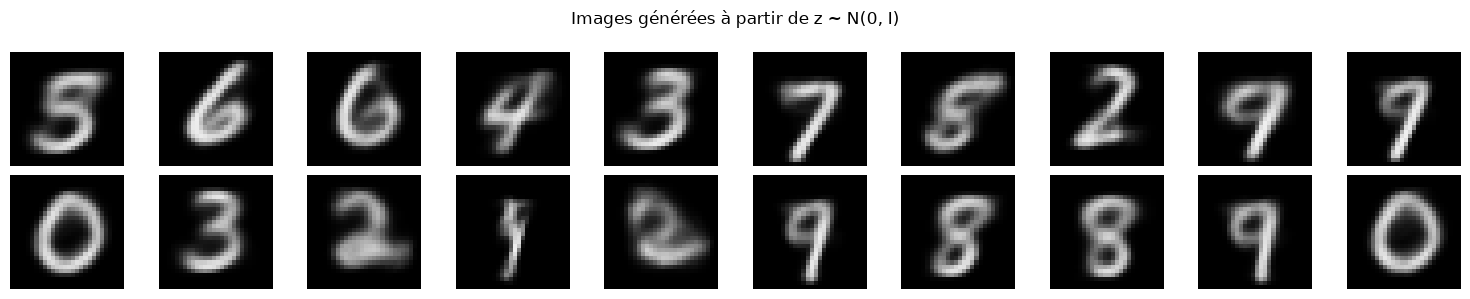

In [8]:
torch.manual_seed(456)
with torch.no_grad():
    z_random = torch.randn(20, 2, device=device)
    generated_images = vae.decode(z_random).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Images générées à partir de z ~ N(0, I)")
plt.tight_layout()
plt.show()


### Exploration d’une grille latente


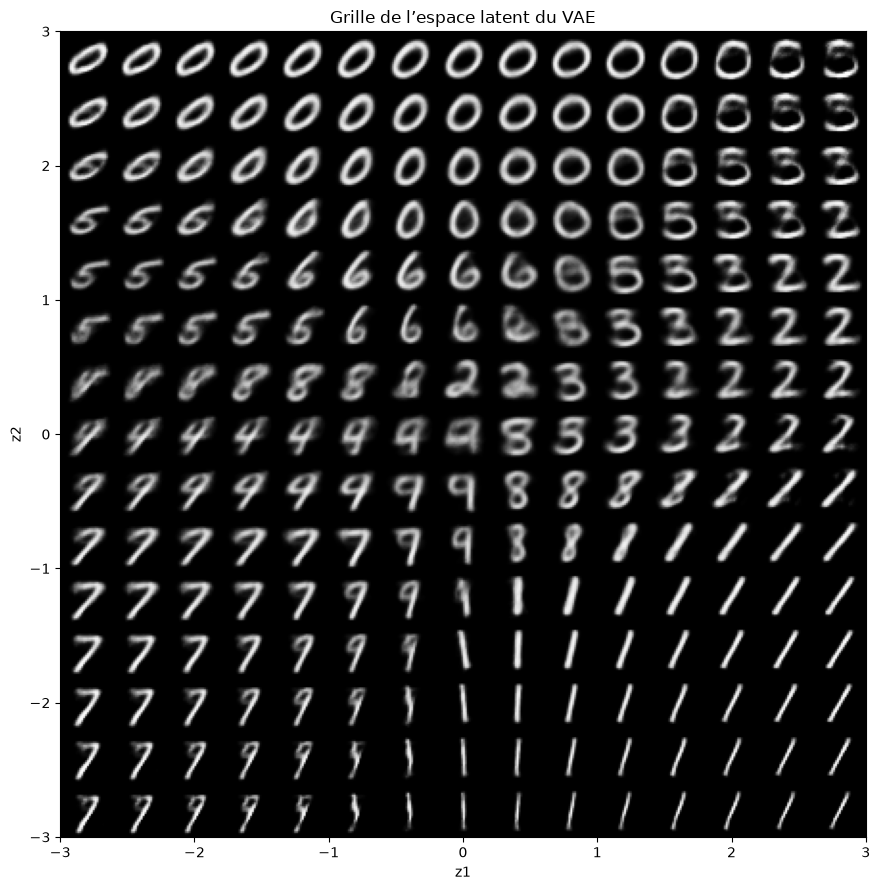

In [9]:
grid_x = torch.linspace(-3, 3, 15)
grid_y = torch.linspace(3, -3, 15)
grid_z = torch.tensor([[x.item(), y.item()] for y in grid_y for x in grid_x], device=device)
with torch.no_grad():
    grid_images = vae.decode(grid_z).cpu()
mosaic = grid_images.view(15, 15, 28, 28).permute(0, 2, 1, 3).reshape(420, 420)
plt.figure(figsize=(9, 9))
plt.imshow(mosaic.numpy(), cmap="gray", vmin=0, vmax=1, extent=[-3, 3, -3, 3])
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Grille de l’espace latent du VAE")
plt.tight_layout()
plt.show()


### Interpolation entre deux images


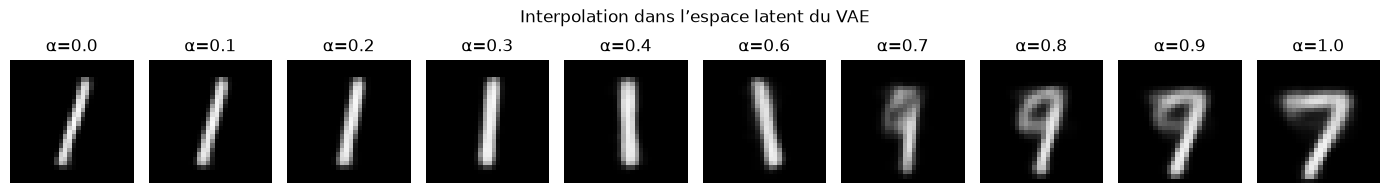

In [10]:
index_1 = (test_dataset.targets == 1).nonzero(as_tuple=True)[0][0].item()
index_7 = (test_dataset.targets == 7).nonzero(as_tuple=True)[0][0].item()
endpoints = torch.stack([test_dataset[index_1][0], test_dataset[index_7][0]]).to(device)
with torch.no_grad():
    endpoint_mu, _ = vae.encode(endpoints)
    alphas = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    interpolated_z = (1 - alphas) * endpoint_mu[0] + alphas * endpoint_mu[1]
    interpolated_images = vae.decode(interpolated_z).cpu()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(interpolated_images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"α={alphas[i].item():.1f}")
    ax.axis("off")
plt.suptitle("Interpolation dans l’espace latent du VAE")
plt.tight_layout()
plt.show()
